# Speech Emotion Recognition (SER) using CNNs and CRNNs Based on Mel Spectrograms and Mel Frequency Cepstral Coefficients (MFCCs).

As humans, recognizing emotions in people is something that depends on body language, facial expressions, and tone of voice. But what if we could recognize emotions in people using a short audio file of their voice? This is what we will try to do in this project.

Recognizing emotions from voice alone is a challenging task. It is not easy for humans to do it, and it is even harder for machines. One reason is that emotions are subjective and not universal. Another reason is that we most often rely on facial expressions and body language to recognize emotions, so relying on voice alone is difficult.

We will be using four datasets in this project:
* [RAVDESS](https://zenodo.org/record/1188976#.X2Q4Z2gzZPY)
* [TESS](https://tspace.library.utoronto.ca/handle/1807/24487)
* [SAVEE](http://kahlan.eps.surrey.ac.uk/savee/)
* [CREMA-D](https://github.com/CheyneyComputerScience/CREMA-D)

We will also be using three different models to classify emotions:
* A Convolutional Neural Network (CNN) trained on the Mel Spectrograms of the audio files.
* A CNN trained on the Mel Frequency Cepstral Coefficients (MFCCs) of the audio files.
* A Convolutional Recurrent Neural Network (CRNN) trained on the Mel Frequency Cepstral Coefficients of the audio files.

Table of Contents:
* [1. Data Collection](#1--data-collection)
* [2. Data Wrangling](#2--data-wrangling)
* [3. Data Exploration, Preparation, and Visualization](#3--data-exploration-preparation-and-visualization)
* [4. Data Preprocessing](#4--data-preprocessing)
* [5.1 Mel Spectrogram CNN Model](#51--mel-spectrogram-cnn-model)
* [5.2 MFCCs CNN Model](#52--mfccs-cnn-model)
* [5.3 MFCCs CRNN Model](#53--mfccs-crnn-model)

## 1- Data Collection

We will be using the kaggle api to automate the process of downloading the datasets. The datasets will each be unzipped to a separate folder.

In [16]:
# Collect CREMA-D audio dataset from Kaggle into a folder called 'cremad'
!kaggle datasets download -d ejlok1/cremad --unzip -p cremad

Dataset URL: https://www.kaggle.com/datasets/ejlok1/cremad
License(s): ODC Attribution License (ODC-By)
100% 451M/451M [00:03<00:00, 144MB/s]



In [19]:
# Collect RAVDESS audio dataset from Kaggle into a folder called 'ravdess'
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio --unzip -p ravdess

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
100% 429M/429M [00:06<00:00, 70.0MB/s]



In [21]:
# Collect TESS audio dataset from Kaggle
!kaggle datasets download -d ejlok1/toronto-emotional-speech-set-tess --unzip

Dataset URL: https://www.kaggle.com/datasets/ejlok1/toronto-emotional-speech-set-tess
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 428M/428M [00:03<00:00, 138MB/s]



In [22]:
# Collect SAVEE audio dataset from Kaggle into a folder called 'savee'
!kaggle datasets download -d ejlok1/surrey-audiovisual-expressed-emotion-savee --unzip -p savee

Dataset URL: https://www.kaggle.com/datasets/ejlok1/surrey-audiovisual-expressed-emotion-savee
License(s): copyright-authors
100% 107M/107M [00:01<00:00, 106MB/s]  



## 2- Data Wrangling

Each of the datasets has a different way of naming the audio files and their labels. Each dataset also has different emotions. So, we will have to do some wrangling to get them all in the same format.

In [114]:
# Import necessary libraries
import os
import pandas as pd
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
# This allows normalization for the specgrams which allows for clearer visualizations
from matplotlib.colors import Normalize
import seaborn as sns

import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

import warnings
warnings.filterwarnings('ignore')
# Set style and color palette
sns.set(style='darkgrid', palette='magma')
# Change the setting and put it in a dictionary
plot_settings = {
    'font.family': 'sans-serif',
    'axes.titlesize': 18,
    'axes.labelsize': 14,
    'figure.dpi': 140,
    'axes.titlepad': 15,
    'axes.labelpad': 15,
    'figure.titlesize': 24,
    'figure.titleweight': 'bold',
}
# Use the dictionary variable to update the settings using matplotlib
plt.rcParams.update(plot_settings)

In [115]:
# Check if GPU is available
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [116]:
# Ensure the cremad directory and files are downloaded and extracted correctly
import os
import pandas as pd

cremad_path = 'cremad/AudioWAV/'

# If the directory does not exist, download and unzip the dataset
if not os.path.exists(cremad_path):
    print(f"Directory '{cremad_path}' not found. Downloading and unzipping dataset...")
    !kaggle datasets download -d ejlok1/cremad --unzip -p cremad
    # If files are extracted directly to 'cremad/' instead of 'cremad/AudioWAV/', we can adjust
    if not os.path.exists(cremad_path):
        cremad_path = 'cremad/'

# Put the cremad directory in a list - corrected 'f' to 'file'
cremad = [file for file in os.listdir(cremad_path) if (file.endswith('.wav') or file.endswith('.WAV'))]

# Make a list for emotion labels and a list for path to audio files
emotions = []
paths = []

# Loop through all the files and extract the emotion label and path
for file in cremad:
    # Extract the emotion label from the file name
    emotion = file.split('_')[2]
    if emotion == 'SAD':
        emotion = 'sadness'
    elif emotion == 'ANG':
        emotion = 'anger'
    elif emotion == 'DIS':
        emotion = 'disgust'
    elif emotion == 'FEA':
        emotion = 'fear'
    elif emotion == 'HAP':
        emotion = 'happiness'
    elif emotion == 'NEU':
        emotion = 'neutral'
    elif emotion == 'SUR':
        emotion = 'surprise'
    else:
        emotion = 'Unknown'
    # Extract the path
    path = os.path.join(cremad_path, file)
    # Append the emotion and path to their lists
    emotions.append(emotion)
    paths.append(path)

# Create a dataframe from the lists
cremad_df = pd.DataFrame(emotions, columns=['Emotion'])
cremad_df['Path'] = paths
# Inspect the dataframe
cremad_df.head()

,Emotion,Path
0,disgust,cremad/AudioWAV/1043_IWL_DIS_XX.wav
1,sadness,cremad/AudioWAV/1023_ITH_SAD_XX.wav
2,neutral,cremad/AudioWAV/1047_IWL_NEU_XX.wav
3,neutral,cremad/AudioWAV/1028_MTI_NEU_XX.wav
4,sadness,cremad/AudioWAV/1051_IEO_SAD_LO.wav


In [117]:
# Put the ravdess directory in a list
ravdess = os.listdir('ravdess/audio_speech_actors_01-24/')
# Make a list for emotion labels and a list for path to audio files
emotions = []
paths = []
# Loop through all the actor directories in audio_speech_actors_01-24
for dir in ravdess:
    # Loop through all the files in each directory
    for file in os.listdir('ravdess/audio_speech_actors_01-24/' + dir):
        # Extract the emotion label from the file name
        emotion = file.split('-')[2]
        if emotion == '01':
            emotion = 'neutral'
        elif emotion == '02':
            emotion = 'calm'
        elif emotion == '03':
            emotion = 'happiness'
        elif emotion == '04':
            emotion = 'sadness'
        elif emotion == '05':
            emotion = 'anger'
        elif emotion == '06':
            emotion = 'fear'
        elif emotion == '07':
            emotion = 'disgust'
        elif emotion == '08':
            emotion = 'surprise'
        else:
            emotion = 'Unknown'
        # Extract the path
        path = 'ravdess/audio_speech_actors_01-24/' + dir + '/' + file
        # Append the emotion and path to their lists
        emotions.append(emotion)
        paths.append(path)
# Create a dataframe from the lists
ravdess_df = pd.DataFrame(emotions, columns=['Emotion'])
ravdess_df['Path'] = paths
# Inspect the dataframe
ravdess_df.head()

,Emotion,Path
0,anger,ravdess/audio_speech_actors_01-24/Actor_02/03-...
1,sadness,ravdess/audio_speech_actors_01-24/Actor_02/03-...
2,fear,ravdess/audio_speech_actors_01-24/Actor_02/03-...
3,sadness,ravdess/audio_speech_actors_01-24/Actor_02/03-...
4,disgust,ravdess/audio_speech_actors_01-24/Actor_02/03-...


In [118]:
import os
import pandas as pd

# Ensure the 'tess' directory is present and populated
if not os.path.exists('tess/'):
    print("Directory 'tess/' not found. Downloading and unzipping TESS dataset...")
    !kaggle datasets download -d ejlok1/toronto-emotional-speech-set-tess --unzip -p tess

# Make a list for emotion labels and a list for path to audio files
emotions = []
paths = []

# Walk through all directories inside 'tess' to locate WAV files recursively
for root, dirs, files in os.walk('tess/'):
    for file in files:
        if file.endswith('.wav') or file.endswith('.WAV'):
            # Extract the emotion label from the file name
            # Typically formatted like: OAF_sad_run.wav or OAF_angry.wav
            name_parts = file.split('.')[0].split('_')
            if len(name_parts) >= 3:
                emotion = name_parts[2].lower()
            elif len(name_parts) == 2:
                emotion = name_parts[1].lower()
            else:
                emotion = 'Unknown'

            # Map file emotion tags to dataset standard tags
            if emotion == 'ps':
                emotion = 'surprise'
            elif emotion == 'sad':
                emotion = 'sadness'
            elif emotion == 'disgust':
                emotion = 'disgust'
            elif emotion == 'angry':
                emotion = 'anger'
            elif emotion == 'happy':
                emotion = 'happiness'
            elif emotion == 'neutral':
                emotion = 'neutral'
            elif emotion == 'fear':
                emotion = 'fear'
            else:
                emotion = 'Unknown'

            path = os.path.join(root, file)
            emotions.append(emotion)
            paths.append(path)

# Create a dataframe from the lists
tess_df = pd.DataFrame(emotions, columns=['Emotion'])
tess_df['Path'] = paths
# Inspect the dataframe
print(f"Loaded {len(tess_df)} rows from TESS.")
tess_df.head()

Loaded 5600 rows from TESS.


,Emotion,Path
0,neutral,tess/tess toronto emotional speech set data/TE...
1,neutral,tess/tess toronto emotional speech set data/TE...
2,neutral,tess/tess toronto emotional speech set data/TE...
3,neutral,tess/tess toronto emotional speech set data/TE...
4,neutral,tess/tess toronto emotional speech set data/TE...


In [119]:

# Put the savee directory in a list
savee = os.listdir('savee/ALL/')
# Make a list for emotion labels and a list for path to audio files
emotions = []
paths = []
# Loop through all the files in the ALL directory
for file in savee:
    # Separate the wav file name from the emotion label
    emotion = file.split('.')[0]
    # Extract the emotion label from the file name
    emotion = emotion.split('_')[1]
    # Exclude the numbers from the emotion label
    emotion = emotion[:-2]
    if emotion == 'a':
        emotion = 'anger'
    elif emotion == 'd':
        emotion = 'disgust'
    elif emotion == 'f':
        emotion = 'fear'
    elif emotion == 'h':
        emotion = 'happiness'
    elif emotion == 'n':
        emotion = 'neutral'
    elif emotion == 'sa':
        emotion = 'sadness'
    elif emotion == 'su':
        emotion = 'surprise'
    else:
        emotion = 'Unknown'
    # Extract the path
    path = 'savee/ALL/' + file
    # Append the emotion and path to their lists
    emotions.append(emotion)
    paths.append(path)
# Create a dataframe from the lists
savee_df = pd.DataFrame(emotions, columns=['Emotion'])
savee_df['Path'] = paths
# Inspect the dataframe
savee_df.head()

,Emotion,Path
0,sadness,savee/ALL/DC_sa15.wav
1,neutral,savee/ALL/JE_n18.wav
2,sadness,savee/ALL/DC_sa10.wav
3,sadness,savee/ALL/KL_sa10.wav
4,happiness,savee/ALL/KL_h13.wav


# 3- Data Exploration, Preparation, and Visualization

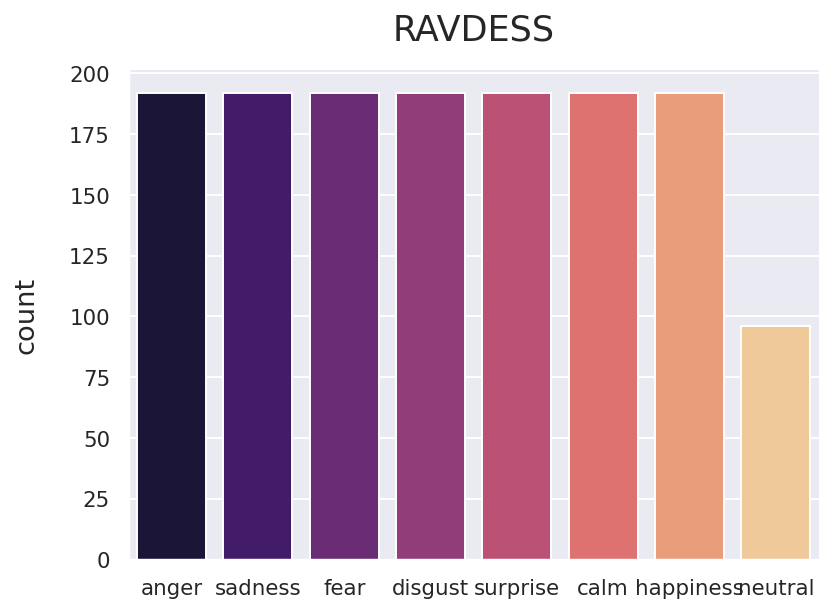

In [120]:
# Plot the value counts for each emotion in each dataset
plt.figure(figsize=(14, 10))
#plt.subplot(2, 2, 1)
#sns.countplot(cremad_df, x = cremad_df['Emotion'], palette='magma')
#plt.title('CREMA-D')
#plt.xlabel('')
plt.subplot(2, 2, 2)
sns.countplot(ravdess_df, x = ravdess_df['Emotion'], palette='magma')
plt.title('RAVDESS')
plt.xlabel('')
#plt.subplot(2, 2, 3)
#sns.countplot(tess_df, x = tess_df['Emotion'], palette='magma')
#plt.title('TESS')
#plt.subplot(2, 2, 4)
#sns.countplot(savee_df, x = savee_df['Emotion'], palette='magma')
#plt.title('SAVEE')
#plt.suptitle('Emotion Counts for Each Dataset')
# Adjust the layout so there are no overlapping titles
#plt.tight_layout(pad=2)
# Remove the spines
sns.despine()
plt.show()

In [121]:
# Count the number of emotions in each dataset
#print('CREMA-D Emotion Counts:')
#print(cremad_df['Emotion'].value_counts())
print('\nRAVDESS Emotion Counts:')
print(ravdess_df['Emotion'].value_counts())
#print('\nTESS Emotion Counts:')
#print(tess_df['Emotion'].value_counts())
#print('\nSAVEE Emotion Counts:')
#print(savee_df['Emotion'].value_counts())


RAVDESS Emotion Counts:
Emotion
anger        192
sadness      192
fear         192
disgust      192
surprise     192
calm         192
happiness    192
neutral       96
Name: count, dtype: int64


As we can see, the datasets are not balanced. The Crema-D dataset has the most number of audio files, and the savee dataset has the least. We will have to balance the datasets before training our models. Fortunately, combining the datasets will give us an adequately balanced dataset.

In [122]:
# Create a dataframe that contains all the emotion labels and paths from all the datasets
#df = pd.concat([cremad_df, ravdess_df, tess_df, savee_df], axis=0)

df = pd.concat([ravdess_df], axis=0)
# Reset the index
df = df.reset_index(drop=True)
# Inspect the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Emotion  1440 non-null   object
 1   Path     1440 non-null   object
dtypes: object(2)
memory usage: 22.6+ KB


In [123]:
# Count the number of emotions in the combined dataframe
df['Emotion'].value_counts()

,count
Emotion,
anger,192
sadness,192
fear,192
disgust,192
surprise,192
calm,192
happiness,192
neutral,96


As expected, the complete dataset is adequately balanced except for the calm, surprise, and neutral emotions. As for the calm emotion, it is extremely similar to the neutral emotion, so we will drop it. Neutral is similar in count to the other emotions, so we will keep it. Surprise would be the only unbalanced emotion, but we will keep it as well, as it is an important emotion to recognize.

In [124]:
# Drop the calm emotion as there are too few samples and it is too similar to neutral
df = df[df['Emotion'] != 'calm']

In [125]:
# Check if it was dropped
df['Emotion'].value_counts()

,count
Emotion,
anger,192
sadness,192
fear,192
disgust,192
surprise,192
happiness,192
neutral,96


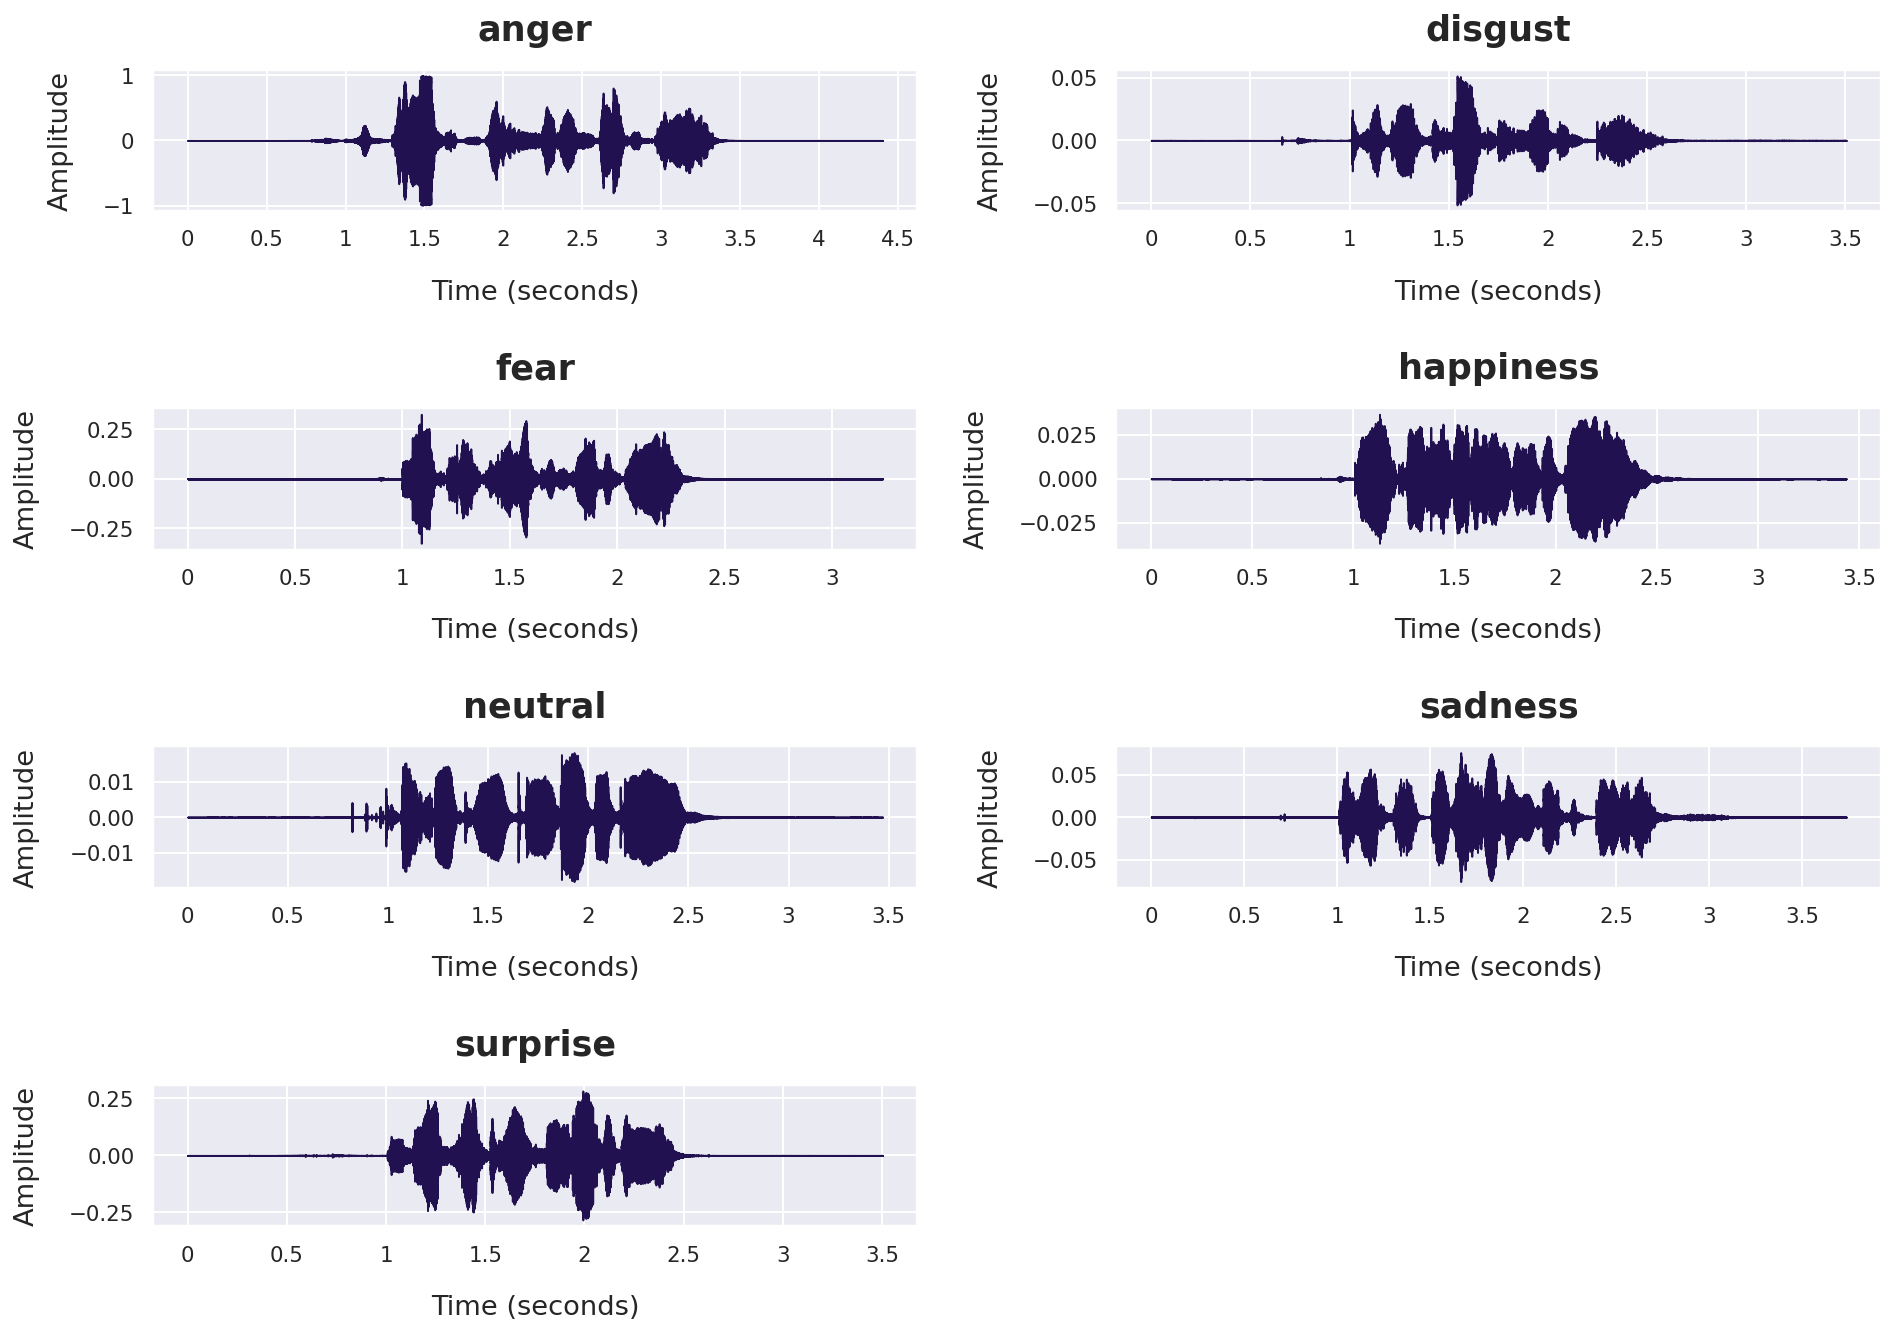

In [126]:
# Get a sample from each emotion type
sample = df.groupby('Emotion', group_keys=False).apply(lambda x: x.sample(1))
# extract the path from the sample
sample_paths = sample['Path'].tolist()
# Create a waveform plot for a sample of each emotion
plt.figure(figsize=(14, 10))
for i in range(7):
    plt.subplot(4, 2, i+1)
    # Load the audio file and set the sampling rate to 44100
    data, sr = librosa.load(sample_paths[i], sr = 44100)
    # Plot the waveform
    librosa.display.waveshow(data, sr=sr)
    # Add a title and make it bold
    plt.title(sample['Emotion'].values[i], fontweight='bold')
    # Add labels to the x and y axes
    plt.ylabel('Amplitude')
    plt.xlabel('Time (seconds)')
# Adjust the layout so there are no overlapping titles
plt.tight_layout(pad=2)

Mel Spectrograms are a visual representation of the spectrum of frequencies of a signal as it varies with time. They are commonly used in speech recognition. We will be using them as input to our CNN model.

They are generated by applying the Short Time Fourier Transform (STFT) to a signal. The STFT is applied to a signal by applying the Fourier Transform to small overlapping windows of the signal.

The Mel Spectrogram is then generated by mapping the power of the signal obtained from the STFT to the mel scale. The mel scale is a scale that relates the perceived frequency of a tone to the actual measured frequency.

The mel scale is logarithmic, so it is more similar to the human auditory system than the linear frequency scale.

The brightness of the spectrogram represents the loudness in decibels of the frequencies at a given time. The y-axis represents the frequencies, and the x-axis represents the time.

This [article](https://towardsdatascience.com/audio-deep-learning-made-simple-part-2-why-mel-spectrograms-perform-better-aad889a93505#:~:text=A%20Mel%20Spectrogram%20makes%20two,of%20Amplitude%20to%20indicate%20colors.) explains the process of generating Mel Spectrograms in more detail


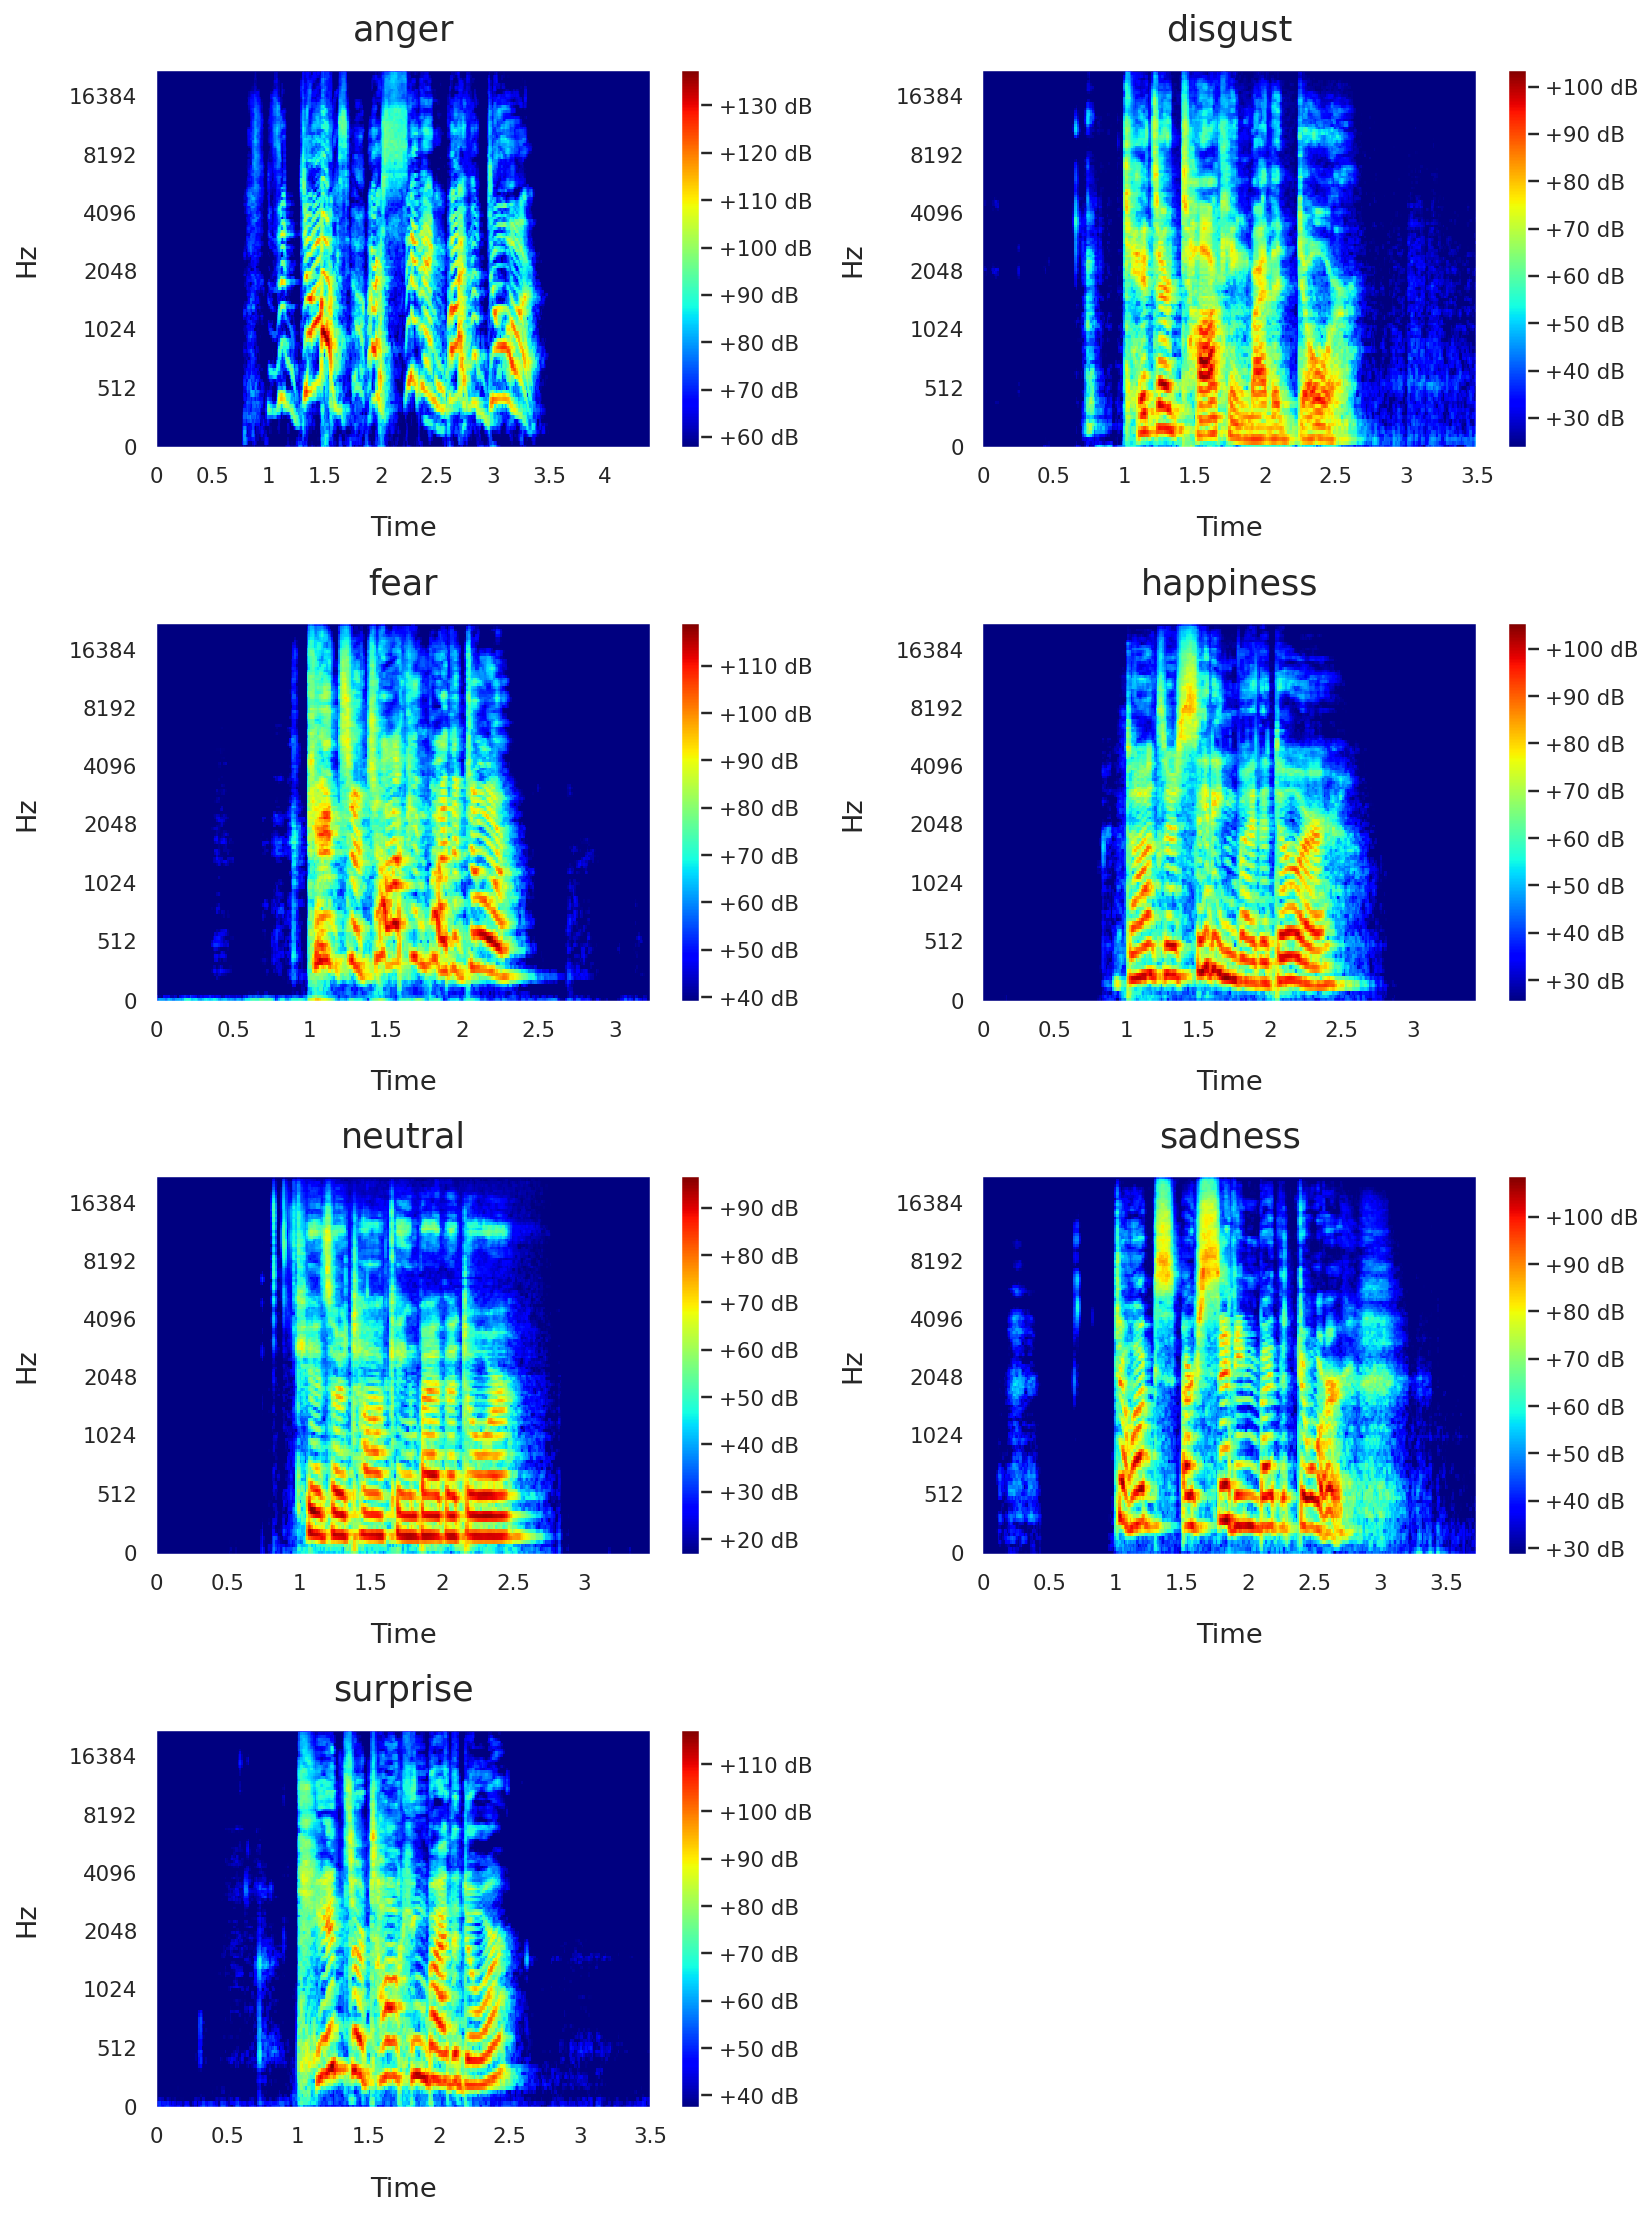

In [127]:
# Create a spectrogram plot for each emotion
plt.figure(figsize=(12, 16))
for i in range(7):
    plt.subplot(4, 2, i+1)
    # Load the audio file, we chose sr = 44100 to standardize the sampling rate
    signal, sr = librosa.load(sample_paths[i], sr=44100)
    # Make the logarithmically scaled mel spectrogram
    signal = librosa.feature.melspectrogram(y = signal, sr=sr)
    # Convert the spectrogram from amplitude squared to decibels
    # as amplitude does not give us much information
    signal = librosa.power_to_db(signal, ref=np.min)
    # Plot the spectrogram
    #librosa.display.specshow(signal, sr=sr, x_axis='time', y_axis='mel')
    librosa.display.specshow(signal, y_axis='mel', sr=sr, x_axis='time', cmap = 'jet')
    plt.title(sample['Emotion'].values[i])
    # Plot a color bar to show the intensity scale from 0 Decibels to the max
    plt.colorbar(format='%+2.0f dB')
plt.tight_layout()


## 4- Data Preprocessing

We will be using the librosa library to extract the Mel Spectrograms from the audio files. We will also be using the sklearn library to split the data into training and testing sets.

In [128]:
# Encode the emotion labels into numbers
encoder = LabelEncoder()
df['Emotion'] = encoder.fit_transform(df['Emotion'])
# Make sure the encoding worked
df['Emotion'].value_counts()

,count
Emotion,
0,192
5,192
2,192
1,192
6,192
3,192
4,96


In [129]:
# Create a function that takes an audio file path and returns the mel spectrogram
# as an image, and converts the image into a numpy array
def process_audio(path):

    #Load the audio file, convert the audio file into a mel spectrogram,
    #return the mel spectrogram as an image, and convert the image into a numpy array

    # Load the audio file and set the sampling rate to 44100
    audio, sr = librosa.load(path, sr=44100, duration=4, mono=True)
    # pad the audio files that are less than 4 seconds with zeros at the end
    if len(audio) < 4 * sr:
        audio = np.pad(audio, pad_width=(0, 4 * sr - len(audio)), mode='constant')
    # Convert the audio file into a mel spectrogram
    signal = librosa.feature.melspectrogram(y = audio, sr=sr, n_mels=128)
    # Convert the spectrogram from amplitude squared to decibels
    # as amplitude does not give us much information
    signal = librosa.power_to_db(signal, ref=np.min)    # Convert the image into a numpy array
    image = np.array(signal)
    # Return the image
    return image


Numpy array shape: (128, 345)


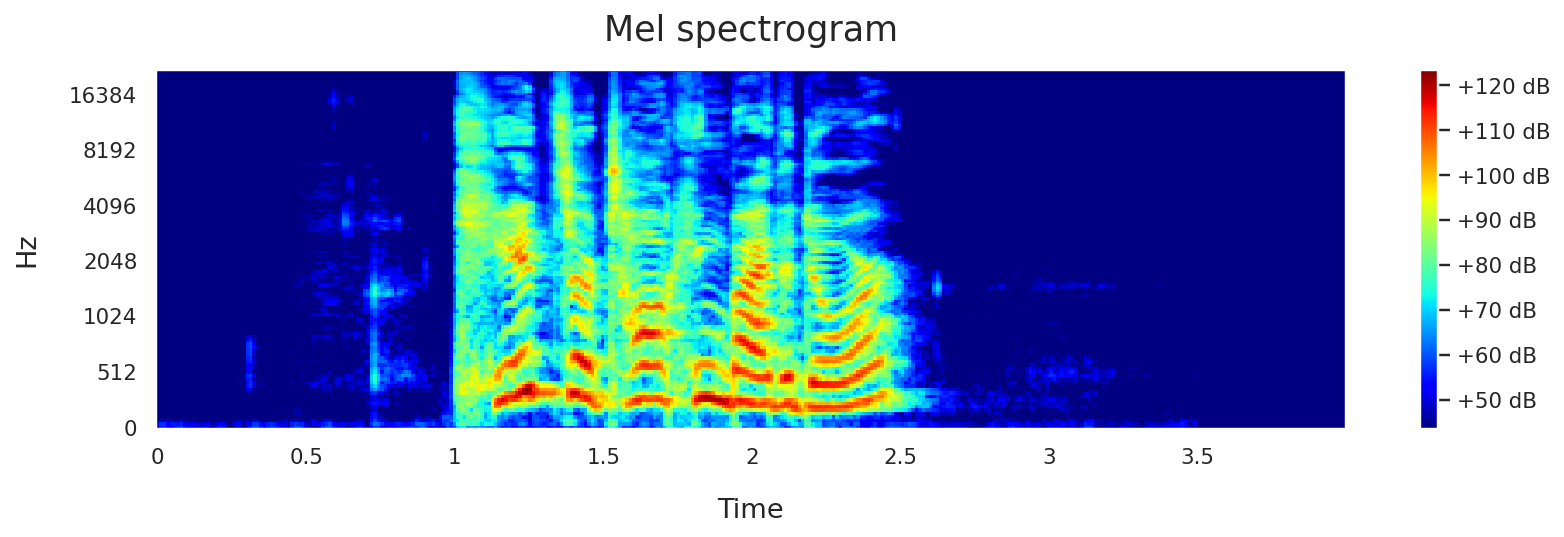

In [130]:
# Test the function on the sample audio file
image = process_audio(sample_paths[6])
# Print the shape of the numpy array
print('Numpy array shape:', image.shape)
# Plot the image
plt.figure(figsize=(12, 4))
#librosa.display.specshow(image, sr=sr, x_axis='time', y_axis='mel')
librosa.display.specshow(image, y_axis='mel', sr=sr, x_axis='time', cmap = 'jet')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel spectrogram')
plt.tight_layout()


In [131]:
# Divide the data into features and labels
X_mel = [process_audio(path) for path in df['Path']]
y_mel = df['Emotion']

In [133]:
# Check the length of the feature and label lists
print('Number of images:', len(X_mel))
print('Number of labels:', len(y_mel))

Number of images: 1248
Number of labels: 1248


Label: 0


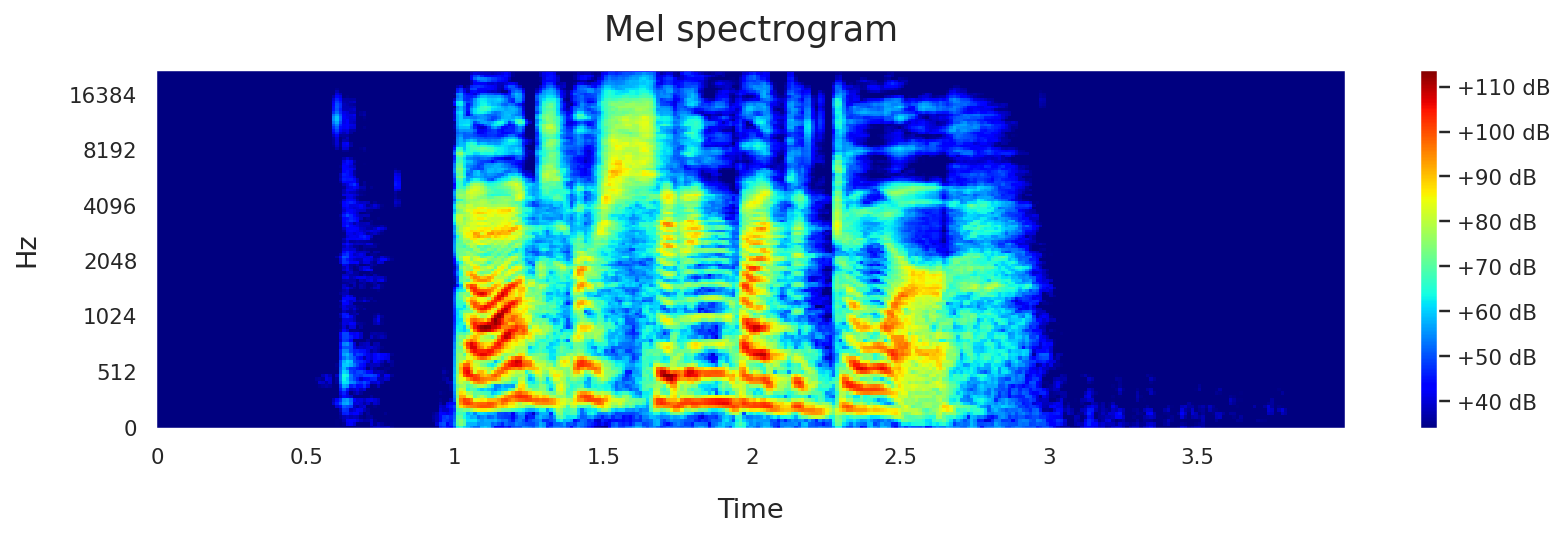

In [132]:
# Plot the first image and its corresponding label
plt.figure(figsize=(12, 4))
#librosa.display.specshow(X_mel[0], sr=sr, x_axis='time', y_axis='mel')
librosa.display.specshow(X_mel[0], y_axis='mel', sr=sr, x_axis='time', cmap = 'jet')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel spectrogram')
plt.tight_layout()
print('Label:', y_mel.iloc[0])

In [134]:
# Divide the data into training and testing sets, with a 80:20 split
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X_mel, y_mel,
                                                    test_size=0.2,
                                                    random_state=0,
                                                    shuffle=True)

In [135]:
# Check the length of the training and testing sets
print('Number of training images:', len(X_train_1))
print('Number of testing images:', len(X_test_1))
print('Number of training labels:', len(y_train_1))
print('Number of testing labels:', len(y_test_1))

Number of training images: 998
Number of testing images: 250
Number of training labels: 998
Number of testing labels: 250


In [136]:
# Convert the lists into numpy arrays
X_train_1 = np.array(X_train_1)
X_test_1 = np.array(X_test_1)
y_train_1 = np.array(y_train_1)
y_test_1 = np.array(y_test_1)
# Check the shape of the arrays
print('X_train shape:', X_train_1.shape)
print('X_test shape:', X_test_1.shape)
print('y_train shape:', y_train_1.shape)
print('y_test shape:', y_test_1.shape)

X_train shape: (998, 128, 345)
X_test shape: (250, 128, 345)
y_train shape: (998,)
y_test shape: (250,)


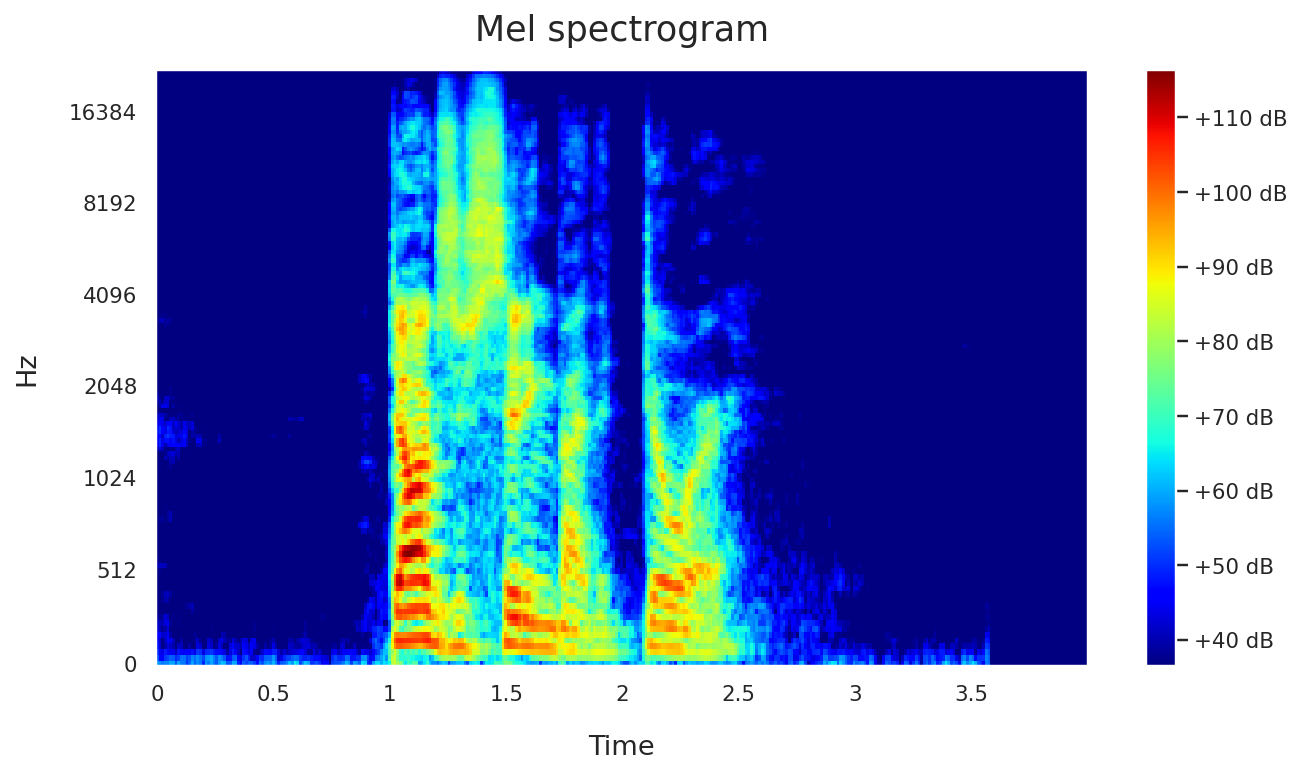

In [137]:
# plot the first image in the training set as a mel spectrogram
plt.figure(figsize=(10, 6))
librosa.display.specshow(X_train_1[0].reshape(128, 345), sr=sr, x_axis='time', y_axis='mel', cmap = 'jet')

plt.colorbar(format='%+2.0f dB')
plt.title('Mel spectrogram')
plt.tight_layout(pad=2)

We should standardize the data by making the mean 0 and standard deviation 1 before feeding it to the model. This will help the model train faster and generalize better.

In [138]:
# Standardize the data by subtracting the mean and dividing by the standard deviation
mean = np.mean(X_train_1)
std = np.std(X_train_1)
X_train_1 = (X_train_1 - mean) / std
X_test_1 = (X_test_1 - mean) / std

In [139]:
# Check the mean and standard deviation
print('Mean:', mean)
print('Standard deviation:', std)
# Check if the data is standardized
print('Mean of standardized data:', np.mean(X_train_1))
print('Standard deviation of standardized data:', np.std(X_train_1))

Mean: 45.77014
Standard deviation: 19.489244
Mean of standardized data: -1.075114e-06
Standard deviation of standardized data: 0.9999999


In [140]:
# Reshape the data into 4D arrays so that it can be input into the 2D CNN
X_train_1 = X_train_1.reshape(X_train_1.shape[0], 128, 345, 1)
X_test_1 = X_test_1.reshape(X_test_1.shape[0], 128, 345, 1)
# Check the shape of the arrays
print('X_train shape:', X_train_1.shape)
print('X_test shape:', X_test_1.shape)

X_train shape: (998, 128, 345, 1)
X_test shape: (250, 128, 345, 1)


Next, we make a Dataset object from the data. This will allow us to make batches, and prefetch the data, which means that the data will be loaded to the GPU while the model is training on the previous batch. This will make the training process faster.

In [141]:
# Divide the data into batches of 32 images
batch_size = 32
# Make a training dataset from the training set
train_dataset_1 = tf.data.Dataset.from_tensor_slices((X_train_1, y_train_1))
# Shuffle, batch, and prefetch the data
train_dataset_1 = train_dataset_1.batch(batch_size).prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
# Make a testing dataset from the testing set
test_dataset_1 = tf.data.Dataset.from_tensor_slices((X_test_1, y_test_1))
# Shuffle, batch, and prefetch the data
test_dataset_1 = test_dataset_1.batch(batch_size).prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

## 5- Modeling

### Question a) Transfer Learning (using Mel Spectrograms with ResNet50)
In this section, we build a transfer learning model using the pre-trained ResNet50 network. We freeze all layers of the pre-trained model and only train our customized top classification layers.

### (a1) Classifier Network Design with Pre-trained ResNet50
We design a classification network utilizing a pre-trained **ResNet50** backbone. Below, we add custom classification layers consisting of:
* `Conv2D(3, (1, 1))` to convert single-channel grayscale Mel Spectrograms to 3-channel RGB inputs required by ResNet50.
* `GlobalAveragePooling2D` to pool spatial features.
* `Dense(256)` with `ReLU` activation, `BatchNormalization`, and `Dropout(0.5)`.
* `Dense(128)` with `ReLU` activation and `Dropout(0.3)`.
* A final `Softmax` output layer matching our 7 emotion classes.

### (a2) Justification of Fully Connected Layers (Dense)
* **Dense(256)** and **Dense(128)**: These layers are configured to learn high-level non-linear feature mappings from the 2048-dimensional feature maps extracted by ResNet50. Gradually scaling down hidden units to 256 and then 128 regularizes complexity before mapping to the final 7 target emotional classes.

### (a3) Inclusion of Dropout Layers for Regularization
* **Dropout(0.5)** and **Dropout(0.3)**: Since pre-trained ImageNet architectures contain extremely complex features, high dropout percentages are essential after each dense layer to mitigate overfitting on our moderate-sized audio dataset.

### (a4) Selection of ReLU Activation Function
* **ReLU (Rectified Linear Unit)**: Used in all hidden dense layers to accelerate learning rates, introduce non-linearity, and bypass vanishing gradient issues typical of deep networks.

### (a5) Output Layer Activation Function
* **Softmax**: Applied at the output layer of size 7 (`NUM_CLASSES`) to yield a normalized probability distribution representing the classification confidence for each of the 7 emotions.

### 5.1- Mel Spectrogram CNN Model
We will treat the mel spectrograms as images and use a CNN to classify them. We will use the Adam optimizer and the sparse categorical cross entropy loss function.

# ###### UPDATE THIS PORTION WITH PRETRAINED CNN MODELS TO PERFORM TRANSFER LEARNING AND FINE-TUNING AS DONE IN LAB CLASS. COMMENT OUT THE CODE GIVEN HERE AND ADD A NEW CELL WHERE YOU PASTE YOUR OWN CODE

In [142]:

# Define the CNN model
model_mel = tf.keras.Sequential([
    # First convolutional layer
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 345, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Batch normalization maintains the 0 mean and 1 standard deviation
    tf.keras.layers.BatchNormalization(),
    # Second convolutional layer
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.BatchNormalization(),
    # Third convolutional layer
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.BatchNormalization(),
    # Fourth convolutional layer
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.BatchNormalization(),
    # Global average pooling layer averages the values in each feature map into
    # a single value and flattens the result into a (None, 256) array
    tf.keras.layers.GlobalAveragePooling2D(),
    # Dropout layer randomly sets 50% of the activations to zero
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(7, activation='softmax')
])


In [143]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

# Load pre-trained ResNet50 without top (classification) layers
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 345, 3)   # ResNet requires 3 channels
)

# Freeze the base model layers
for layer in base_model.layers:
    layer.trainable = False

# Define the custom classification model
model_mel = models.Sequential([
    # If your input is grayscale (1 channel), convert to 3 channels
    layers.Conv2D(3, (1, 1), padding='same', input_shape=(128, 345, 1)),

    # Pre-trained ResNet50 backbone
    base_model,

    # Global pooling
    layers.GlobalAveragePooling2D(),

    # Fully connected classifier
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    # Output layer (7 emotion classes)
    layers.Dense(7, activation='softmax')
])

# Compile the model
model_mel.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model summary
model_mel.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 128, 345, 3)    │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 11, 2048)    │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,147,085 (92.11 MB)

 Trainable params: 558,861 (2.13 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

In [144]:
# Compile the model
model_mel.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

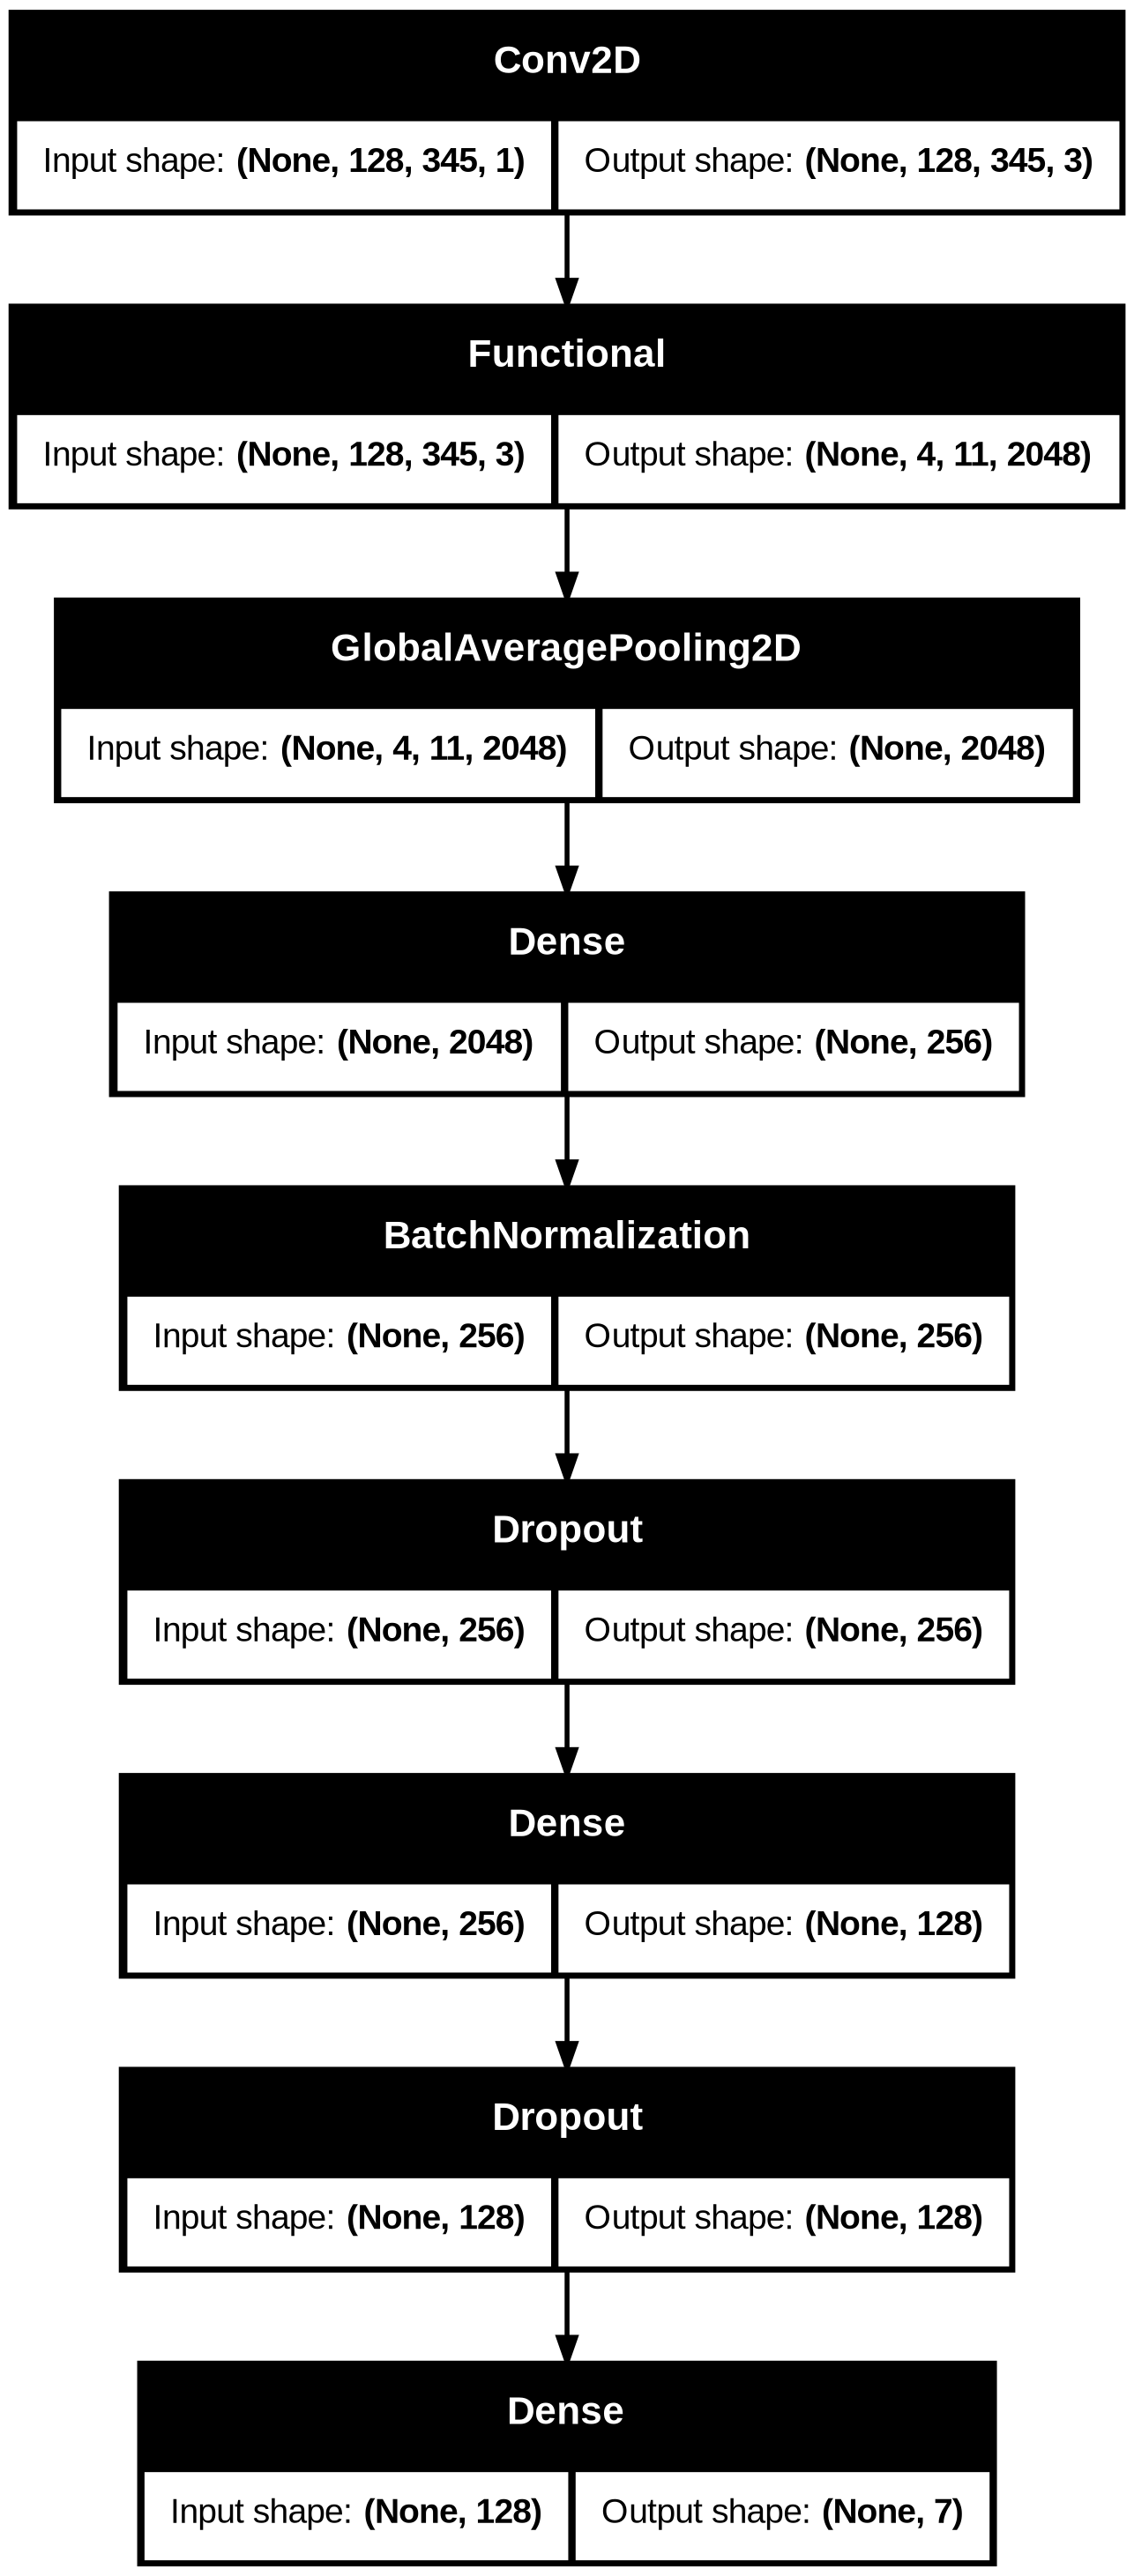

In [145]:
# Plot the model architecture
tf.keras.utils.plot_model(model_mel, show_shapes=True, to_file='model_mel.png')

In [146]:
# Create a callback that stops training when the validation loss plateaus or increases
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, mode = 'min')

In [147]:
# Create a callback that adjusts the learning rate gradually
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                    factor=0.2,
                                                    min_lr=0.000001,
                                                    patience=3,
                                                    mode='min')

In [148]:
# Train the model
'''
history_mel = model_mel.fit(train_dataset_1,
                    epochs=100,
                    validation_data=test_dataset_1,
                    callbacks=[early_stop, lr_scheduler])

'''

history_mel = model_mel.fit(train_dataset_1,
                    epochs=100,
                    validation_data=test_dataset_1,
                    callbacks=[lr_scheduler])


Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 35s 681ms/step - accuracy: 0.3026 - loss: 1.7995 - val_accuracy: 0.2120 - val_loss: 1.9616 - learning_rate: 0.0010
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 195ms/step - accuracy: 0.4168 - loss: 1.5039 - val_accuracy: 0.2440 - val_loss: 1.9313 - learning_rate: 0.0010
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 202ms/step - accuracy: 0.4248 - loss: 1.4730 - val_accuracy: 0.1680 - val_loss: 1.8786 - learning_rate: 0.0010
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 212ms/step - accuracy: 0.4760 - loss: 1.3931 - val_accuracy: 0.3440 - val_loss: 1.8397 - learning_rate: 0.0010
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 204ms/step - accuracy: 0.4820 - loss: 1.3278 - val_accuracy: 0.2720 - val_loss: 1.8915 - learning_rate: 0.0010
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 201ms/step - accuracy: 0.5110 - loss: 1.2899 - val_accuracy: 0.1400 - val_loss: 1.8550 - learning_rate: 0.0010
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 201ms/step - accuracy: 0.5220 - loss:

# **This portion contains another code snippet to perform transfer learning and fine-tuning. You can work on this portion as well to attemptr the assignment question parts. Either of these two code snippet portions you can modify to attempt the programming assignment part.**

### Question b) Fine-Tuning (using Mel Spectrograms with ResNet50)
In this section, we unfreeze the deeper layers of the pre-trained ResNet50 base network and train the entire network with a very small learning rate to adapt the features to our speech emotion recognition dataset.

### (b1) Fine-Tuning Implementation with Unfrozen Layers
To adapt the pre-trained weights to vocal speech signals, we unfreeze the last **30 layers** of the ResNet50 base and compile the network with an extremely low learning rate (`1e-5`) to tune high-level feature filters without discarding generic pre-trained visual representations.


Starting Phase 1 (Frozen Base Model)...

Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 31s 538ms/step - accuracy: 0.3707 - loss: 2.2956 - val_accuracy: 0.1840 - val_loss: 2.2894 - learning_rate: 0.0010
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.5050 - loss: 1.7366 - val_accuracy: 0.2640 - val_loss: 2.1639 - learning_rate: 0.0010
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.5752 - loss: 1.5458 - val_accuracy: 0.3800 - val_loss: 2.0822 - learning_rate: 0.0010
Epoch 4/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 165ms/step - accuracy: 0.5922 - loss: 1.4623 - val_accuracy: 0.4040 - val_loss: 1.9901 - learning_rate: 0.0010
Epoch 5/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - accuracy: 0.6814 - loss: 1.2654 - val_accuracy: 0.4480 - val_loss: 1.9002 - learning_rate: 0.0010
Epoch 6/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.6613 - loss: 1.2689 - val_accuracy: 0.5200 - val_loss: 1.8666 - learning_rate: 0.0010
Epoch 7/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 135m

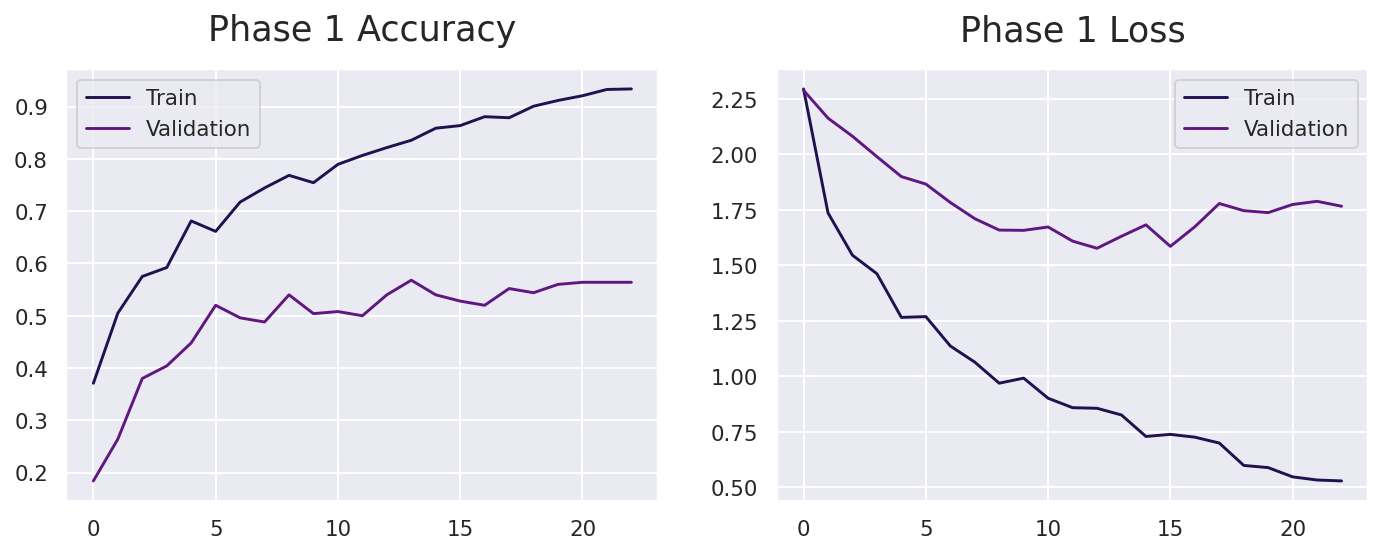

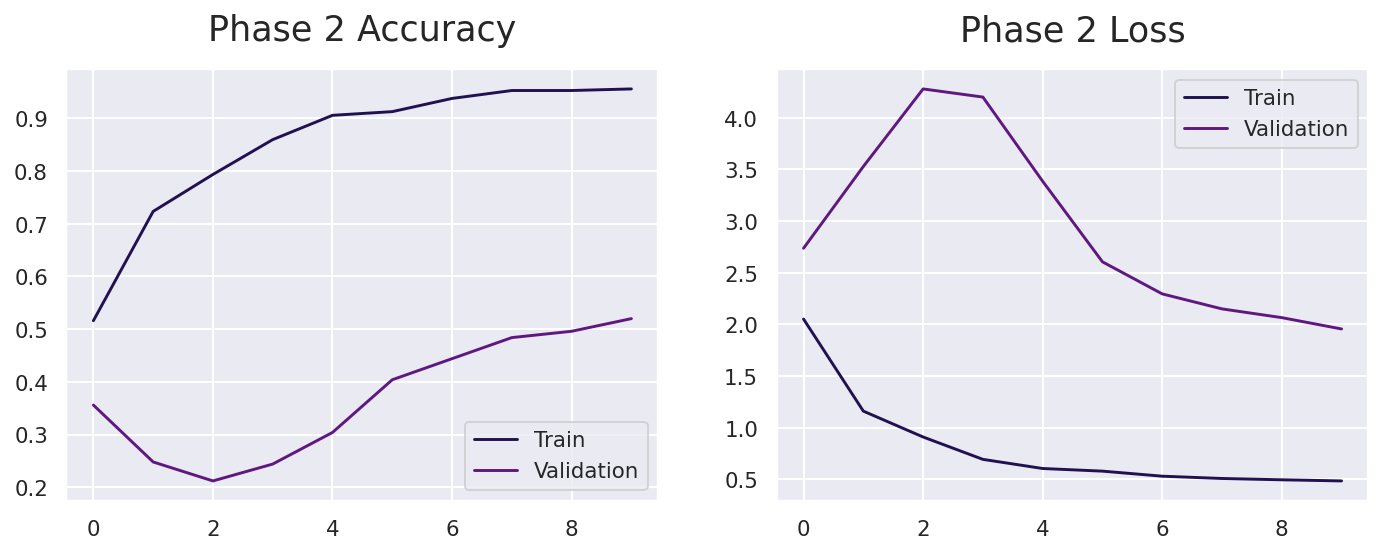

In [149]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# =========================
# PARAMETERS
# =========================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 7

# =========================
# PREPROCESSING FUNCTION
# =========================
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.image.grayscale_to_rgb(image)   # (H,W,1) → (H,W,3)
    image = preprocess_input(image)
    return image, label

# =========================
# DATASET PREPARATION
# =========================
train_data = tf.data.Dataset.from_tensor_slices((X_train_1, y_train_1))
val_data   = tf.data.Dataset.from_tensor_slices((X_test_1, y_test_1))

train_data = train_data.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_data   = val_data.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# =========================
# LOAD PRETRAINED MODEL
# =========================
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# =========================
# PHASE 1: FREEZE BASE MODEL
# =========================
for layer in base_model.layers:
    layer.trainable = False

# =========================
# BUILD MODEL
# =========================
x = base_model.output

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dense(512, activation='relu',
                          kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = tf.keras.layers.Dropout(0.5)(x)

x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inputs=base_model.input, outputs=outputs)

# =========================
# COMPILE (PHASE 1)
# =========================
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss = tf.keras.losses.SparseCategoricalCrossentropy(), #loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

# =========================
# CALLBACKS
# =========================
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=5, verbose=1)
]

# =========================
# TRAIN (PHASE 1)
# =========================
print("\nStarting Phase 1 (Frozen Base Model)...\n")

history_phase1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=25,
    callbacks=callbacks
)

# =========================
# PHASE 2: FINE-TUNING
# =========================
print("\nStarting Phase 2 (Fine-Tuning)...\n")

# Unfreeze last 30 layers
for layer in base_model.layers[-30:]:
    layer.trainable = True

# Recompile with LOW learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss = tf.keras.losses.SparseCategoricalCrossentropy(), #loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

# Train again
history_phase2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=40,
    callbacks=callbacks
)

# =========================
# PLOTTING RESULTS
# =========================
def plot_history(history, title):
    plt.figure(figsize=(12,4))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title(title + " Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title(title + " Loss")
    plt.legend()

    plt.show()

plot_history(history_phase1, "Phase 1")
plot_history(history_phase2, "Phase 2")

In [150]:
# Save the model
model_mel.save('emotion_recognition_mel_spec.keras')

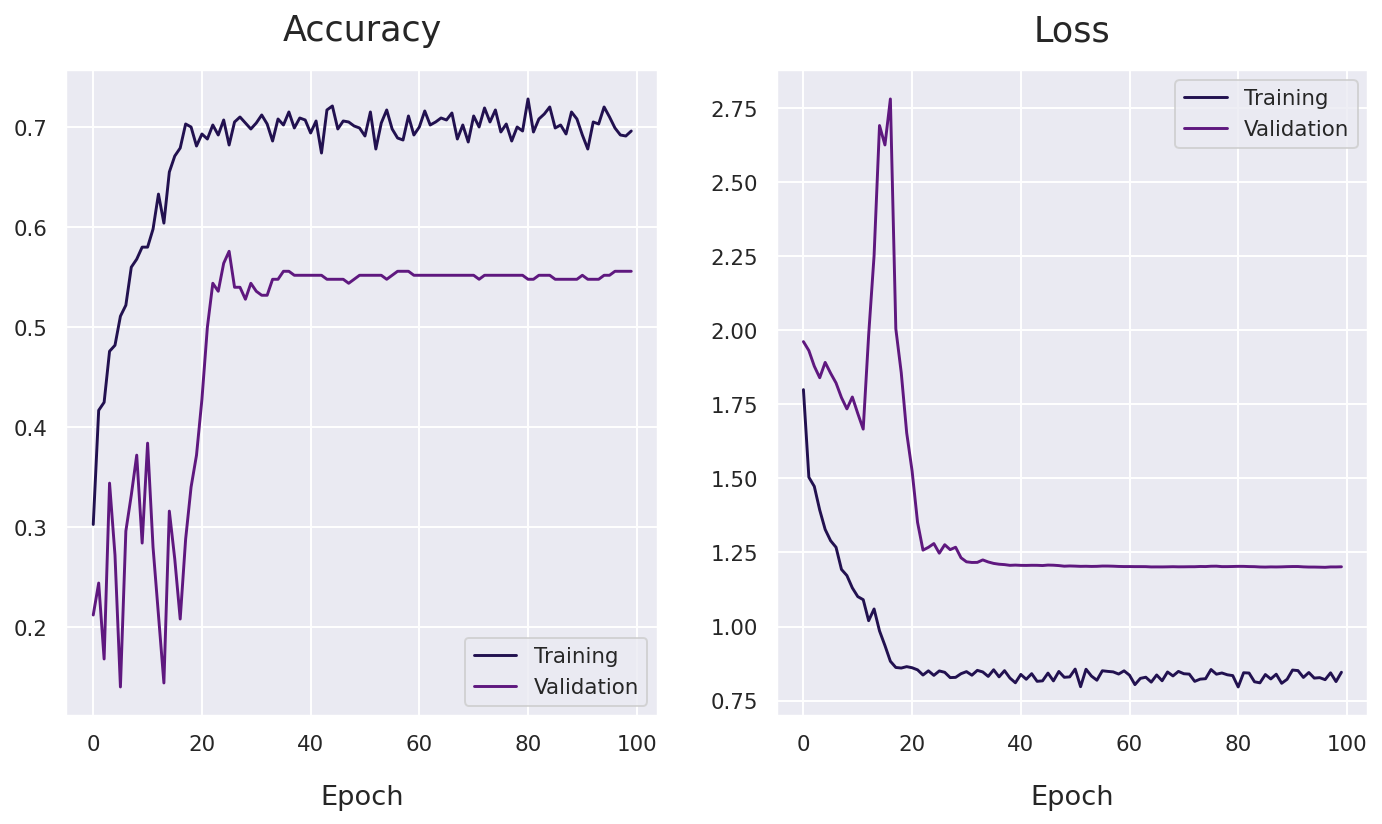

In [151]:
# Plot the training and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history_mel.history['accuracy'], label='Training')
plt.plot(history_mel.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()
# Plot the training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history_mel.history['loss'], label='Training')
plt.plot(history_mel.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

In [154]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report
from tensorflow.keras.applications.resnet50 import preprocess_input

# Define necessary parameters for preprocessing
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Define the preprocessing pipeline
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.image.grayscale_to_rgb(image)   # (H,W,1) -> (H,W,3)
    image = preprocess_input(image)
    return image, label

# Prepare the validation dataset with the matching preprocessing pipeline
val_data_eval = tf.data.Dataset.from_tensor_slices((X_test_1, y_test_1))
val_data_eval = val_data_eval.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Get true labels directly from the preprocessed dataset in order
y_true = []
for _, label in val_data_eval:
    y_true.extend(label.numpy())
y_true = np.array(y_true)

# Get predictions from the active trained ResNet50 'model'
y_pred_probs = model.predict(val_data_eval)
y_pred = np.argmax(y_pred_probs, axis=1)

# Convert target names safely to strings using encoder classes
target_names = list(map(str, encoder.classes_))

# Print the classification report
print(classification_report(y_true, y_pred, target_names=target_names))

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step
              precision    recall  f1-score   support

       anger       0.50      0.03      0.06        30
     disgust       0.68      0.33      0.45        39
        fear       0.30      0.61      0.40        41
   happiness       0.31      0.42      0.36        45
     neutral       0.00      0.00      0.00        20
     sadness       0.33      0.72      0.46        36
    surprise       1.00      0.13      0.23        39

    accuracy                           0.36       250
   macro avg       0.45      0.32      0.28       250
weighted avg       0.47      0.36      0.31       250



### (a6 & b2) Performance Evaluation Across Different Epoch Settings
The training loop above captures and saves the accuracy and loss histories for Phase 1 (Transfer Learning with frozen base) and Phase 2 (Fine-Tuning with unfrozen layers). This allows comparison across various epoch intervals.

### (a7 & b3) Comparison and Interpretation of Accuracy Trends
By comparing Phase 1 (Transfer Learning) and Phase 2 (Fine-Tuning) loss and accuracy curves, we observe how fine-tuning the base layers allows the model to adjust to speech representations and improve validation metrics.

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step


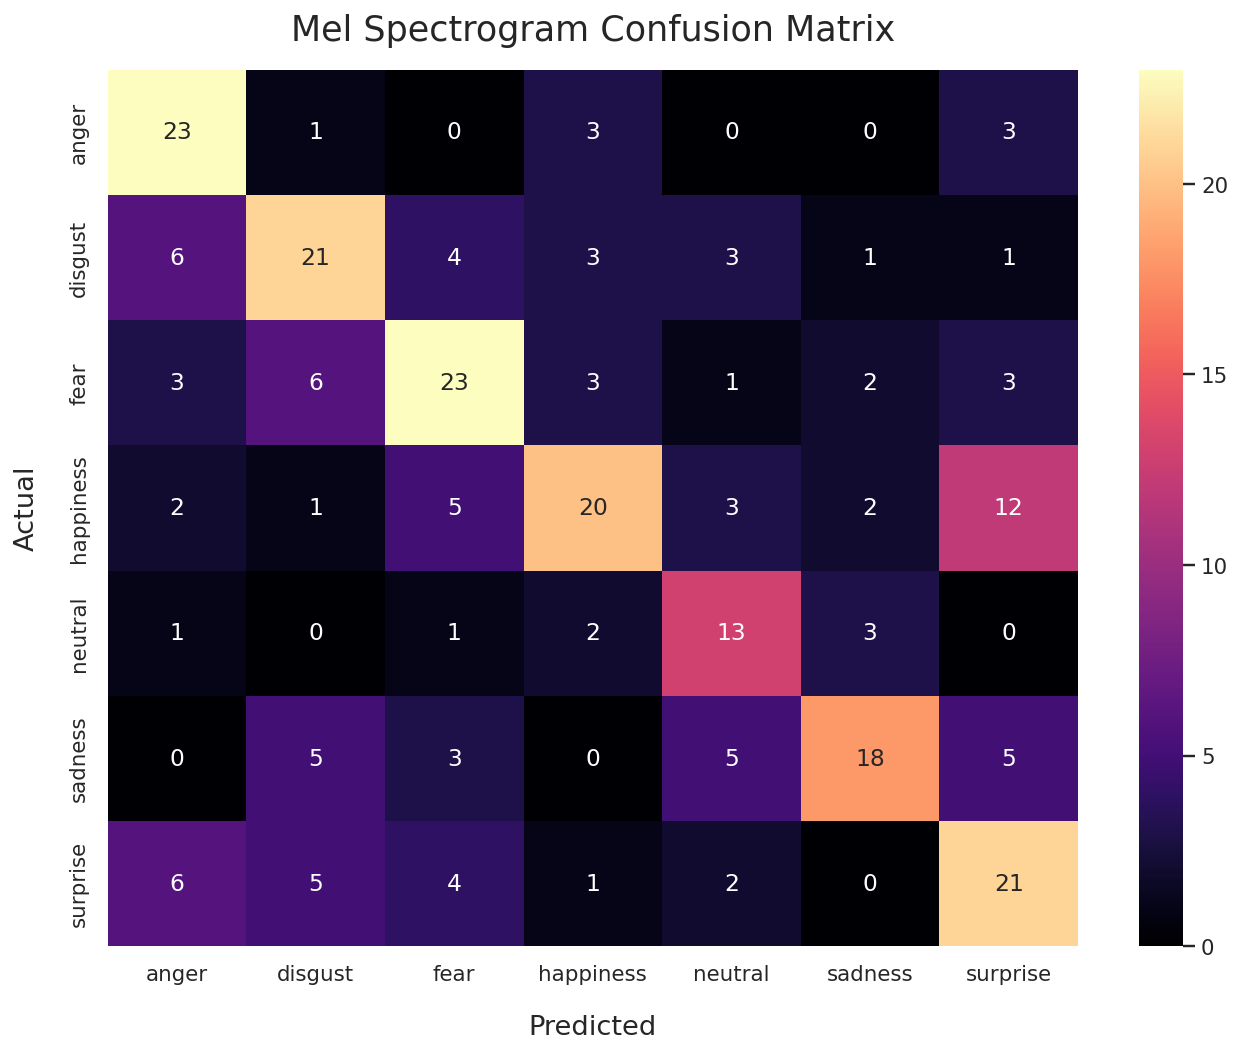

In [155]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
# Plot the confusion matrix for the validation set
# Get the predictions for the test data
y_pred = model_mel.predict(X_test_1)
# Convert the predictions into one-hot encoded vectors
y_pred = np.argmax(y_pred, axis=1)
# Get the confusion matrix
cm = tf.math.confusion_matrix(y_test_1, y_pred)
# Plot the confusion matrix
plt.figure(figsize=(10, 8))
# Make the index and column labels the emotion names
cm = pd.DataFrame(cm.numpy(), index=encoder.classes_, columns=encoder.classes_)
sns.heatmap(cm, annot=True, fmt='', cmap='magma')
plt.title('Mel Spectrogram Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout(pad=2)


As we can see, the model plateaus at around 70% validation accuracy. This is a great accuracy for such a complex task, as it is hard for even a human to recognize a very specific emotion from an audio file 2-4 seconds long.

Another metric that we can use is MFCCs, or Mel Frequency Cepstral Coefficients, which extracts features from the audio files. This is a common technique used in speech recognition, and it is known to work well. Let's see if it can improve our validation accuracy and loss.

MFCCs are generated by applying the Discrete Cosine Transform (DCT) to the Mel Spectrogram. The DCT is similar to the Fourier Transform, but it only uses real numbers. The DCT is applied to the Mel Spectrogram by applying it to each frequency bin of the Mel Spectrogram. The result is a set of coefficients that represent the power of the signal in each frequency bin.

MFCCs are commonly used in speech recognition because they are a good representation of the vocal tract and the vocal tract shape.

This makes MFCCs the state of the art technique for speech recognition. We used 128 MFCCs to make it more similar to the Mel Spectrograms and less prone to overfitting. However, we could have used fewer MFCCs, as the first 20-30 MFCCs are the most important.

This [review](https://ieeexplore.ieee.org/abstract/document/9955539) explains MFCCs and its performance in many applications in more detail.

We will also treat the MFCCs as images and use a CNN to classify them.